## Test Calculation (multiplying the flux with the MR from FLEXPART)

In [15]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

### Aligning ERA5 data to FLEXPART OUTGRID

In [31]:
flexpartoutput_filename = '/jetfs/scratch/gbrack/flexpart_output/india_single_10d/grid_time_20150528120000.nc'
era5_filename = '/jetfs/scratch/gbrack/MSC/ERA_SHF_LHF_Pr.nc'

In [32]:
# opening the datasets separately
ds_flexpart = xr.open_dataset(flexpartoutput_filename)
ds_era = xr.open_dataset(era5_filename)

In [33]:
ds_flexpart

<xarray.Dataset> Size: 3GB
Dimensions:     (time: 240, longitude: 840, latitude: 460, height: 7,
                 numpoint: 1, numspec: 1, nageclass: 1, pointspec: 1)
Coordinates:
  * time        (time) datetime64[ns] 2kB 2015-05-28T11:00:00 ... 2015-05-18T...
  * longitude   (longitude) float32 3kB -90.0 -89.75 -89.5 ... 119.2 119.5 119.8
  * latitude    (latitude) float32 2kB -30.0 -29.75 -29.5 ... 84.25 84.5 84.75
  * height      (height) float32 28B 100.0 500.0 1e+03 2e+03 3e+03 5e+03 5e+04
Dimensions without coordinates: numpoint, numspec, nageclass, pointspec
Data variables: (12/15)
    RELCOM      (numpoint) |S45 45B ...
    RELLNG1     (numpoint) float32 4B ...
    RELLNG2     (numpoint) float32 4B ...
    RELLAT1     (numpoint) float32 4B ...
    RELLAT2     (numpoint) float32 4B ...
    RELZZ1      (numpoint) float32 4B ...
    ...          ...
    RELEND      (numpoint) timedelta64[ns] 8B ...
    RELPART     (numpoint) int32 4B ...
    RELXMASS    (numspec, numpoint) float32 4B ...
    LAGE        (nageclass) timedelta64[ns] 8B ...
    ORO         (latitude, longitude) int32 2MB ...
    spec001_mr  (nageclass, pointspec, time, height, latitude, longitude) float32 3GB ...
Attributes: (12/37)
    Conventions:            CF-1.6
    title:                  FLEXPART model output
    git:                    dace3af Mon Nov 24 10:17:47 2025 +0100
    source:                 Version 11.0 (2023-07-11) model output
    history:                2026-05-30 20:05 +0200  created by gbrack on jet1...
    references:             Stohl et al., Atmos. Chem. Phys., 2005, doi:10.51...
    ...                     ...
    ind_source:             1
    ind_receptor:           2
    mquasilag:              0
    nested_output:          2
    sfc_only:               0
    linit_cond:             2

In [34]:
ds_era

<xarray.Dataset> Size: 893MB
Dimensions:     (valid_time: 288, latitude: 461, longitude: 841)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 2kB 2015-05-14 ... 2015-05-25T23:...
  * latitude    (latitude) float64 4kB 85.0 84.75 84.5 ... -29.5 -29.75 -30.0
  * longitude   (longitude) float64 7kB -90.0 -89.75 -89.5 ... 119.5 119.8 120.0
    expver      (valid_time) <U4 5kB ...
Data variables:
    slhf        (valid_time, latitude, longitude) float32 447MB ...
    sshf        (valid_time, latitude, longitude) float32 447MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-05-30T18:13 GRIB to CDM+CF via cfgrib-0.9.1...

In [35]:
# rename time
ds_era_clean = ds_era.rename({'valid_time': 'time'})

# crop era to fit flexpart spatial grid
ds_era_aligned = ds_era_clean.reindex_like(ds_flexpart)

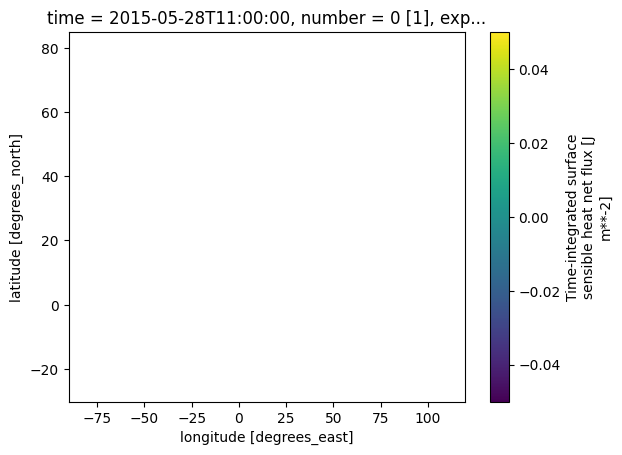

In [36]:
ds_era_aligned.sshf.isel(time=0).plot()

### Calculation

In [37]:
cp = 1004.0  # specific heat constant of dry air (J / kg K)
dt = 3600    # seconds in 1 hour

In [38]:
# get 100m flexpart layer
flexpart_mr = ds_flexpart.spec001_mr.sel(height=slice(0, 3000)).squeeze()

In [39]:
# get heights (and "layer" thicknesses) from flexpart dataset
height_edges = np.insert(flexpart_mr.height.values, 0, 0)
dz_values = np.diff(height_edges)

# turn thicknesses into broadcastable DataArray
dz_da = xr.DataArray(dz_values, coords=[flexpart_mr.height], dims=['height'])

In [40]:
# 3D Energy Multiplication for sshf
hourly_sh_3d = (flexpart_mr * (ds_era_aligned.sshf * -1.0)) / (dt * dz_da)
hourly_lh_3d = (flexpart_mr * (ds_era_aligned.slhf * -1.0)) / (dt * dz_da)

In [41]:
total_sh = hourly_sh_3d.sum(dim=['time', 'height'])
total_lh = hourly_lh_3d.sum(dim=['time', 'height'])

### Let's look at the output

Maximum energy added: 26.0


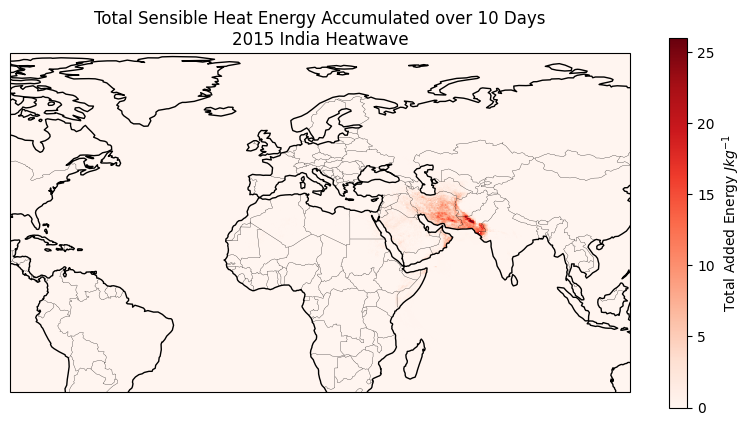

In [42]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

max_energy = total_sh.max().values

my_min = 0
my_max = np.round(max_energy, 0)


mesh = ax.pcolormesh(total_sh.longitude,
                     total_sh.latitude,
                     total_sh,
                     transform=ccrs.PlateCarree(),
                     cmap='Reds',
                     vmin=my_min,
                     vmax=my_max
                    )

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Energy $J kg^{-1}$')

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2)

ax.set_title('Total Sensible Heat Energy Accumulated over 10 Days\n2015 India Heatwave')

print(f'Maximum energy added: {np.round(max_energy, 0)}')

Maximum energy added: 23.0


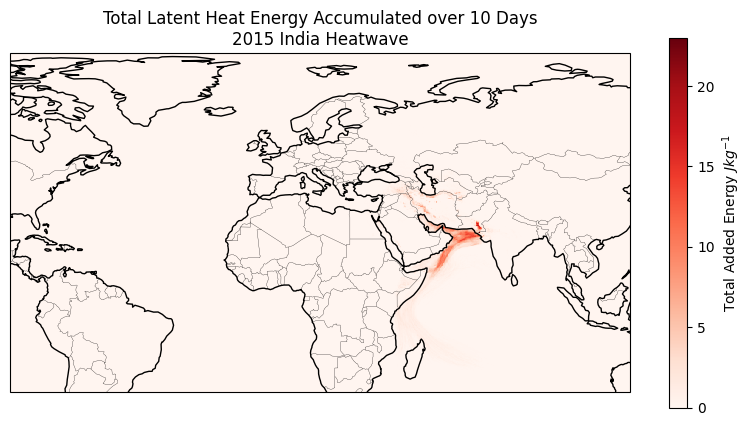

In [43]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6),
                       subplot_kw={'projection': ccrs.PlateCarree()})

max_energy = total_lh.max().values

my_min = 0
my_max = np.round(max_energy, 0)


mesh = ax.pcolormesh(total_lh.longitude,
                     total_lh.latitude,
                     total_lh,
                     transform=ccrs.PlateCarree(),
                     cmap='Reds',
                     vmin=my_min,
                     vmax=my_max
                    )

plt.colorbar(mesh, ax=ax, shrink=0.8, label=r'Total Added Energy $J kg^{-1}$')

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2)

ax.set_title('Total Latent Heat Energy Accumulated over 10 Days\n2015 India Heatwave')

print(f'Maximum energy added: {np.round(max_energy, 0)}')

In [44]:
timeline_sh = hourly_sh_3d.sum(dim=['latitude', 'longitude', 'height'])
timeline_lh = hourly_lh_3d.sum(dim=['latitude', 'longitude', 'height'])

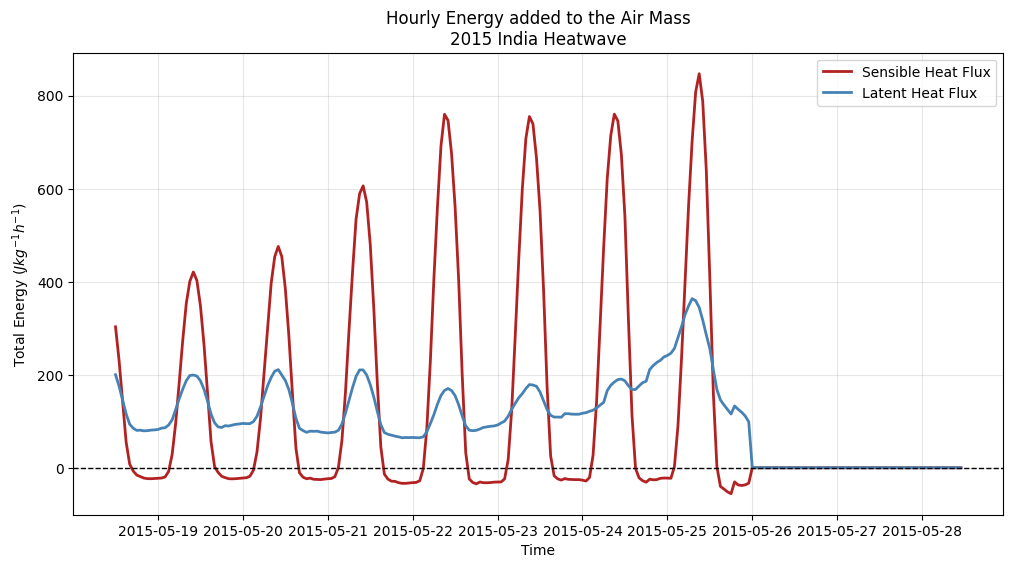

In [45]:
fix, ax = plt.subplots(1, 1, figsize=(12, 6))

ax.plot(timeline_sh.time,
        timeline_sh,
        color='firebrick',
        label='Sensible Heat Flux',
        lw=2
       )

ax.plot(timeline_lh.time,
        timeline_lh,
        color='steelblue',
        label='Latent Heat Flux',
        lw=2
       )

ax.axhline(0, c='k', lw='1', ls='--')

ax.set_title('Hourly Energy added to the Air Mass\n2015 India Heatwave')
ax.set_ylabel(r'Total Energy ($J kg^{-1} h^{-1}$)')
ax.set_xlabel('Time')

ax.grid(True, alpha=0.3)
ax.legend()